# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Regina Ramadhani
- NIM   : 241011400353
- Kelas : Reg C

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 53

In [2]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_set_size = int(n_samples * test_size)

    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]

    if isinstance(X, pd.DataFrame) or isinstance(X, pd.Series):
        return X.iloc[train_indices], X.iloc[test_indices], y.iloc[train_indices], y.iloc[test_indices]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


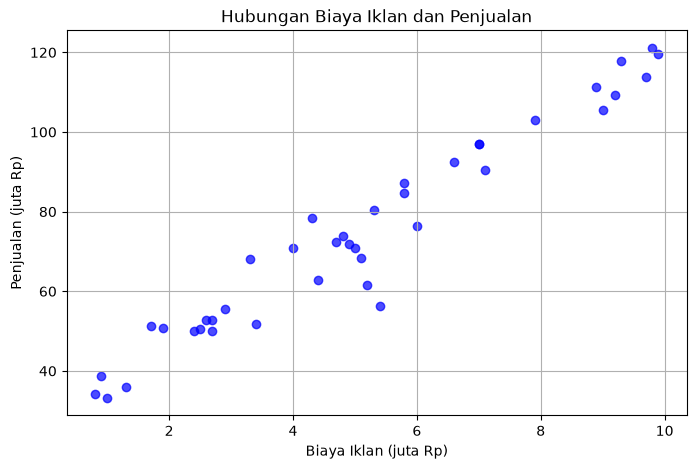

In [3]:
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
print(df_ads.head())
print(f"\nJumlah baris data: {len(df_ads)}")

X_ads = df_ads[['BiayaIklan']].values  # Berbentuk (n, 1)
y_ads = df_ads['Penjualan'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7)
plt.title('Hubungan Biaya Iklan dan Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"X_train shape: {X_train_a.shape}")
print(f"X_test shape : {X_test_a.shape}")
print(f"y_train shape: {y_train_a.shape}")
print(f"y_test shape : {y_test_a.shape}")

X_train shape: (32, 1)
X_test shape : (8, 1)
y_train shape: (32,)
y_test shape : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [20]:
# 1. Implementasi Class LinearRegression menggunakan Normal Equation
class LinearRegression:
    def fit(self, X, y):
        # Menambahkan kolom bias (angka 1) ke matriks X
        X_b = np.c_[np.ones((len(X), 1)), X]
        # Rumus Normal Equation: theta = (X^T * X)^(-1) * X^T * y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        
    def predict(self, X):
        return self.intercept_ + np.dot(X, self.coef_)

# Melatih model dengan data training (X_train_a dan y_train_a dari Soal A2)
model_a3 = LinearRegression()
model_a3.fit(X_train_a, y_train_a)

# 2. Menampilkan nilai intercept (b) dan koefisien (m)
b = model_a3.intercept_
m = model_a3.coef_[0]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"\nPersamaan Garis Regresi: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b) : 26.5629
Koefisien (m) : 9.3264

Persamaan Garis Regresi: y_hat = 26.5629 + 9.3264 * X


**Jawaban A3 (interpretasi):**

* **Intercept ($b$):** Menunjukkan estimasi nilai penjualan ketika biaya iklan sama dengan 0 (tidak ada biaya iklan yang dikeluarkan).
* **Koefisien ($m$):** Menunjukkan bahwa setiap kenaikan biaya iklan sebesar **1 juta Rp**, maka nilai penjualan diproyeksikan akan mengalami peningkatan sebesar **9.3264 juta Rp**.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Evaluasi Train & Test
y_pred_train = model_a3.predict(X_train_a)
y_pred_test = model_a3.predict(X_test_a)

metrics = {
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2'],
    'Train': [
        mean_absolute_error(y_train_a, y_pred_train),
        mean_squared_error(y_train_a, y_pred_train),
        root_mean_squared_error(y_train_a, y_pred_train),
        r2_score(y_train_a, y_pred_train)
    ],
    'Test': [
        mean_absolute_error(y_test_a, y_pred_test),
        mean_squared_error(y_test_a, y_pred_test),
        root_mean_squared_error(y_test_a, y_pred_test),
        r2_score(y_test_a, y_pred_test)
    ]
}

df_metrics = pd.DataFrame(metrics)
print(df_metrics)

  Metric      Train       Test
0    MAE   4.460851   5.119667
1    MSE  36.379717  37.845624
2   RMSE   6.031560   6.151880
3     R2   0.940069   0.948650


**Jawaban A4 (analisis):** 

* **RMSE:** Rata-rata selisih/kesalahan prediksi model terhadap data penjualan yang sebenarnya. Semakin kecil nilainya, semakin akurat prediksi model.
* **$R^2$:** Menunjukkan seberapa banyak variasi penjualan yang berhasil dijelaskan oleh biaya iklan. Jika nilai $R^2$ mendekati 1 (di atas 0.8 atau 80%), maka model dianggap sudah sangat baik.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== Hasil Training Gradient Descent (n_iterations = 5000) ===
LR = 0.001 | Intercept (b): 22.9683 | Koefisien (m): 9.8874
LR = 0.02  | Intercept (b): 26.5629 | Koefisien (m): 9.3264


c:\Users\ReginaRmdni\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\ReginaRmdni\AppData\Local\Temp\ipykernel_8996\1130067554.py:25: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - y_pred) ** 2)
C:\Users\ReginaRmdni\AppData\Local\Temp\ipykernel_8996\1130067554.py:17: RuntimeWarning: overflow encountered in dot
  dw = (2 / n_samples) * np.dot(X.T, (y_pred - y))
C:\Users\ReginaRmdni\AppData\Local\Temp\ipykernel_8996\1130067554.py:21: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.lr * dw


LR = 0.1   | Intercept (b): nan | Koefisien (m): nan

--- Perbandingan dengan Normal Equation (Soal A3) ---
Normal Eq | Intercept (b): 26.5629 | Koefisien (m): 9.3264


c:\Users\ReginaRmdni\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


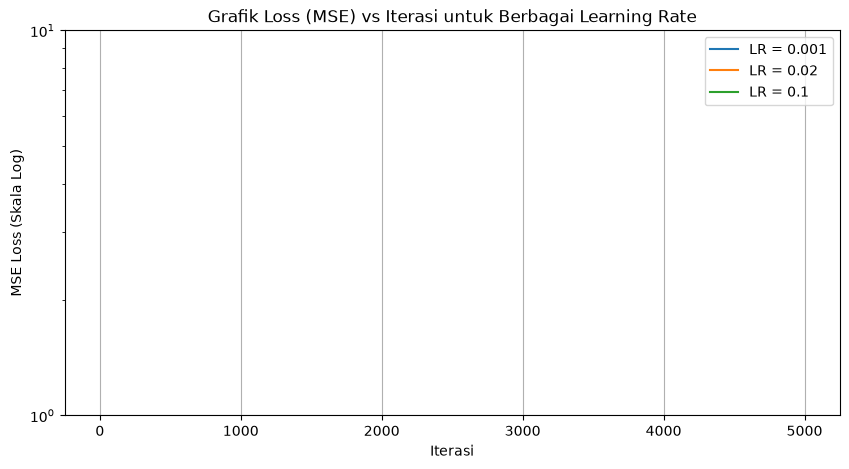

In [21]:
# 1. Class LinearRegressionGD (Gradient Descent)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        
    def fit(self, X, y):
        n_samples = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + np.dot(X, self.coef_)
            
            # Menghitung Gradient
            dw = (2 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (2 / n_samples) * np.sum(y_pred - y)
            
            # Update Parameter
            self.coef_ -= self.lr * dw
            self.intercept_ -= self.lr * db
            
            # Hitung Loss (MSE)
            loss = np.mean((y - y_pred) ** 2)
            self.loss_history.append(loss)

# 2. Eksperimen 3 Learning Rate
learning_rates = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 5))

print("=== Hasil Training Gradient Descent (n_iterations = 5000) ===")
for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model_gd.fit(X_train_a, y_train_a)
    
    print(f"LR = {lr:<5} | Intercept (b): {model_gd.intercept_:.4f} | Koefisien (m): {model_gd.coef_[0]:.4f}")
    plt.plot(model_gd.loss_history, label=f'LR = {lr}')

print("\n--- Perbandingan dengan Normal Equation (Soal A3) ---")
print(f"Normal Eq | Intercept (b): {model_a3.intercept_:.4f} | Koefisien (m): {model_a3.coef_[0]:.4f}")

# 3. Visualisasi Grafik Loss vs Iterasi
plt.yscale('log')
plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('MSE Loss (Skala Log)')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):** 

1. **`LR = 0.001` (Terlalu Lambat):**
   * Langkah pembaruan parameter sangat kecil sehingga penurunan *loss* berjalan lambat.
   * Meskipun stabil dan tidak melompati titik minimum, model membutuhkan iterasi yang jauh lebih banyak untuk konvergen penuh mendekati hasil *Normal Equation*.

2. **`LR = 0.02` (Pas / Optimal):**
   * Nilai *learning rate* ini pas. Nilai *loss* (MSE) turun dengan cepat dan stabil hingga mencapai titik minimum.
   * Nilai *intercept* dan *koefisien* yang dihasilkan sangat mendekati/identik dengan hasil *Normal Equation* pada Soal A3.

3. **`LR = 0.1` (Gagal Konvergen / Divergen):**
   * Nilai *learning rate* terlalu besar untuk skala data tanpa normalisasi (*feature scaling*).
   * Akibatnya, langkah *gradient descent* melompati titik minimum (*overshooting*) secara berlebihan. Nilai *loss* membesar secara eksponensial di tiap iterasi hingga melebihi kapasitas memori penampung angka (*overflow*) dan berubah menjadi `nan` (*exploding gradient*).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

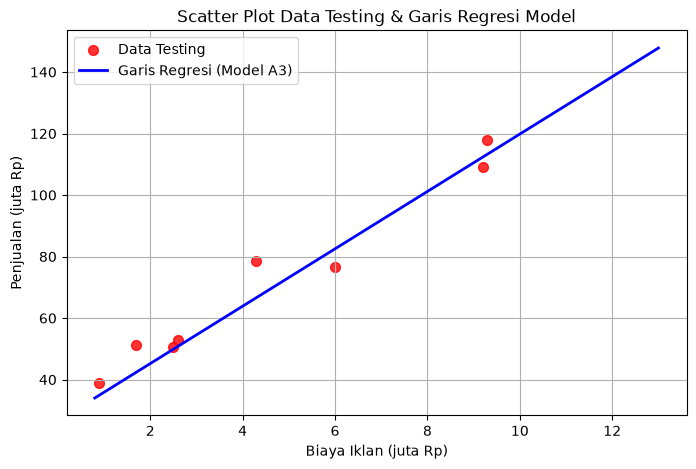

=== Hasil Prediksi Penjualan ===
Biaya Iklan:  4.5 juta Rp  ==>  Estimasi Penjualan: 68.53 juta Rp
Biaya Iklan:  7.0 juta Rp  ==>  Estimasi Penjualan: 91.85 juta Rp
Biaya Iklan: 12.0 juta Rp  ==>  Estimasi Penjualan: 138.48 juta Rp


In [22]:
# 1. Membuat Grafik Scatter Data Testing dan Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing', alpha=0.8, s=50)

# Rentang sumbu X dari rentang terkecil hingga 13 (agar mencakup nilai 12 juta)
x_range = np.linspace(X_ads.min(), 13, 100).reshape(-1, 1)
y_range = model_a3.predict(x_range)

plt.plot(x_range, y_range, color='blue', linewidth=2, label='Garis Regresi (Model A3)')
plt.title('Scatter Plot Data Testing & Garis Regresi Model')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi Penjualan untuk 4.5 Juta, 7 Juta, dan 12 Juta
biaya_iklan_baru = np.array([[4.5], [7.0], [12.0]])
hasil_prediksi = model_a3.predict(biaya_iklan_baru)

print("=== Hasil Prediksi Penjualan ===")
for biaya, pred in zip([4.5, 7.0, 12.0], hasil_prediksi):
    print(f"Biaya Iklan: {biaya:>4.1f} juta Rp  ==>  Estimasi Penjualan: {pred:.2f} juta Rp")

**Jawaban A6 (analisis):**

1. **Prediksi Ekstrapolasi (12 Juta):**
   * Prediksi biaya iklan **12 juta Rp** menghasilkan nilai estimasi penjualan berdasarkan tren linier garis regresi[cite: 1].
   
2. **Tingkat Kepercayaan Hasil Prediksi Ekstrapolasi:**
   * Hasil prediksi untuk 12 juta Rp **kurang bisa dipercaya (memiliki tingkat ketidakpastian yang tinggi)**[cite: 1].
   
3. **Alasan:**
   * **Di Luar Rentang Data Historis:** Model dipelajari dari rentang data *BiayaIklan* pada dataset, sedangkan 12 juta berada jauh di luar rentang sampel historis tersebut[cite: 1].
   * **Prinsip Kejenuhan Pasar (*Law of Diminishing Returns*):** Pada kondisi dunia nyata, hubungan antara biaya iklan dan penjualan tidak selalu linier selamanya. Penambahan biaya iklan yang terlalu besar pada titik tertentu dapat mengalami kejenuhan, kapasitas produksi/operasional yang terbatas, atau jangkauan audiens yang sudah maksimal sehingga peningkatan penjualan bisa melandai.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Spam (1) dan Bukan Spam (0):
Spam
0    35
1    25
Name: count, dtype: int64


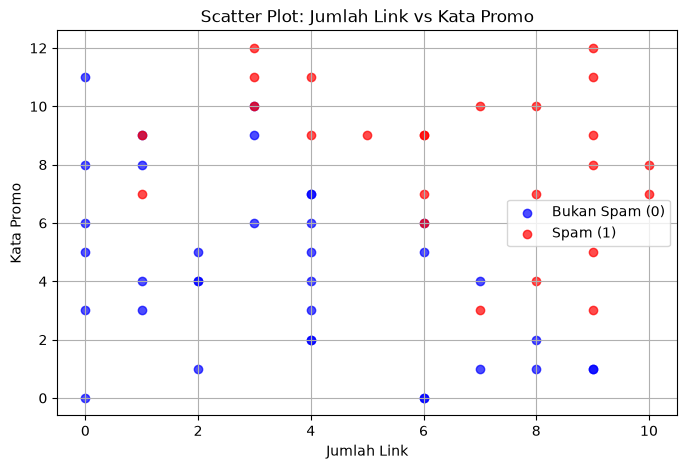

In [24]:
# 1. Load Data & Tampilkan
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama:")
print(df_email.head())
print("\nJumlah Email Spam (1) dan Bukan Spam (0):")
print(df_email['Spam'].value_counts())

# 2. Pisahkan X dan y
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# 3. Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='blue', label='Bukan Spam (0)', alpha=0.7)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='red', label='Spam (1)', alpha=0.7)
plt.title('Scatter Plot: Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b)   : -9.1811
Koefisien (m1, m2): [0.83167983 0.76921259]
Persamaan: P(Spam) = sigmoid(-9.1811 + 0.8317*JumlahLink + 0.7692*KataPromo)


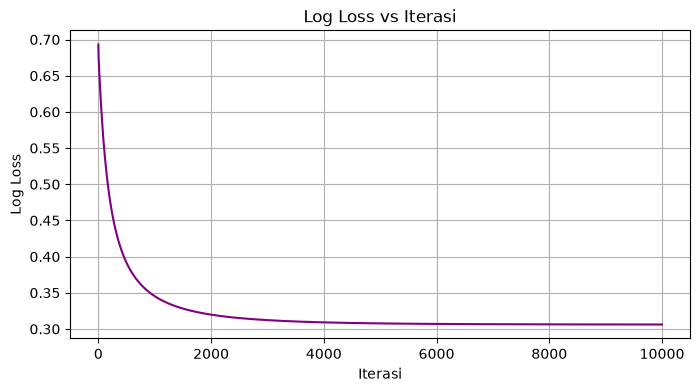

In [26]:
# 1. Split Data
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

# 2. Class Logistic Regression
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        
    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)
            
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
            eps = 1e-15
            y_pred_clipped = np.clip(y_predicted, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            
    def predict_proba(self, X):
        return self._sigmoid(np.dot(X, self.weights) + self.bias)
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# 3. Training Model
model_b = LogisticRegression(learning_rate=0.1, n_iterations=10000)
model_b.fit(X_train_b, y_train_b)

# Tampilkan Intercept & Koefisien
print(f"Intercept (b)   : {model_b.bias:.4f}")
print(f"Koefisien (m1, m2): {model_b.weights}")
print(f"Persamaan: P(Spam) = sigmoid({model_b.bias:.4f} + {model_b.weights[0]:.4f}*JumlahLink + {model_b.weights[1]:.4f}*KataPromo)")

# 4. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 4))
plt.plot(model_b.loss_history, color='purple')
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**

* **Perubahan Loss:** Grafik menunjukkan bahwa nilai *log loss* mengalami penurunan yang sangat signifikan dan tajam pada iterasi-iterasi awal (0 hingga kisaran 1.000 iterasi).
* **Kestabilan Model:** Setelah melewati iterasi awal tersebut, kurva *loss* mendatar secara konsisten hingga iterasi ke-10.000.
* **Kesimpulan:** Nilai *loss* sudah **berhasil turun dan stabil**, yang menandakan bahwa proses *gradient descent* telah konvergen mencapai solusi yang optimal.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [27]:
def confusion_matrix_custom(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def evaluate_classification(y_true, y_pred):
    cm = confusion_matrix_custom(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return accuracy, cm, precision, recall, f1

y_pred_b = model_b.predict(X_test_b)
acc, cm, prec, rec, f1 = evaluate_classification(y_test_b, y_pred_b)
print(f"Accuracy : {acc:.4f}\nPrecision: {prec:.4f}\nRecall   : {rec:.4f}\nF1-Score : {f1:.4f}")
print("\nConfusion Matrix:\n", cm)

Accuracy : 0.9333
Precision: 0.8571
Recall   : 1.0000
F1-Score : 0.9231

Confusion Matrix:
 [[8 1]
 [0 6]]


**Jawaban B3 (analisis):**

1. **Arti Nilai FP dan FN:**
   * **False Positive (FP):** Email penting atau biasa (bukan spam) secara keliru diklasifikasikan sebagai email spam oleh sistem.
   * **False Negative (FN):** Email spam secara keliru diklasifikasikan sebagai email biasa sehingga lolos masuk ke kotak masuk utama (*inbox*).

2. **Kesalahan yang Lebih Merugikan Pengguna:**
   * **False Positive (FP)** jauh lebih merugikan pengguna email.
   * **Alasan:** Jika terjadi FP, pengguna berisiko melewatkan atau tidak membaca pesan penting (seperti panggilan wawancara kerja, instruksi tugas, pengumuman perkuliahan, atau tagihan) karena pesan tersebut terlanjur terlempar ke folder spam. Sedangkan jika terjadi FN, pengguna hanya merasa sedikit terganggu karena harus menghapus email sampah secara manual dari kotak masuk tanpa ada risiko kehilangan informasi penting.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

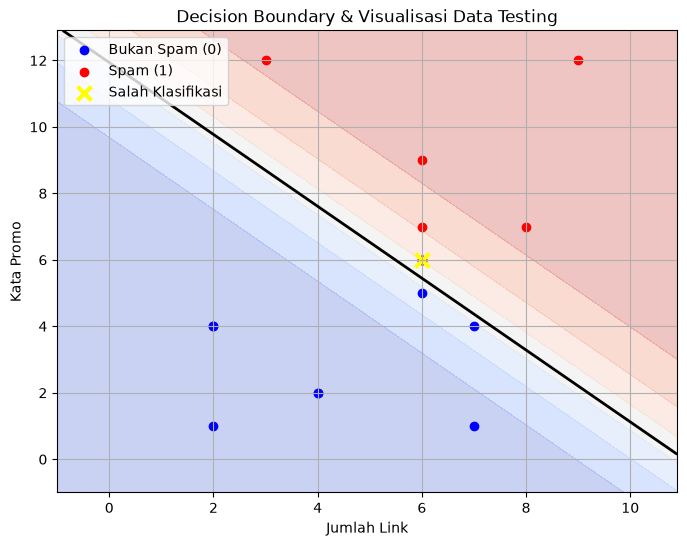

In [28]:
# 1. Plot Data Testing & Decision Boundary
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.1), np.arange(x2_min, x2_max, 0.1))

Z = model_b.predict_proba(np.c_[xx1.ravel(), xx2.ravel()])
Z = Z.reshape(xx1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, Z, alpha=0.3, cmap='coolwarm')
plt.contour(xx1, xx2, Z, levels=[0.5], colors='black', linewidths=2)

# Scatter plot data testing
plt.scatter(X_test_b[y_test_b == 0, 0], X_test_b[y_test_b == 0, 1], color='blue', label='Bukan Spam (0)')
plt.scatter(X_test_b[y_test_b == 1, 0], X_test_b[y_test_b == 1, 1], color='red', label='Spam (1)')

# Menandai data misclassified
misclassified = (y_test_b != y_pred_b)
if np.any(misclassified):
    plt.scatter(X_test_b[misclassified, 0], X_test_b[misclassified, 1], color='yellow', marker='x', s=100, linewidths=3, label='Salah Klasifikasi')

plt.title('Decision Boundary & Visualisasi Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban B4 (analisis):**

1. **Persamaan Decision Boundary:**
   * Garis pemisah (*decision boundary*) terbentuk pada saat nilai probabilitas $P(\text{Spam}) = 0.5$, yang setara dengan kondisi linear $b + m_1 x_1 + m_2 x_2 = 0$.
   * Dengan memasukkan bobot model, didapatkan persamaan garis:
     $$x_2 = -\frac{b + m_1 x_1}{m_2}$$

2. **Analisis Klasifikasi & Area Probabilitas:**
   * **Area Merah (Kanan Atas):** Area dengan probabilitas $P(\text{Spam}) \geq 0.5$, menandakan wilayah prediksi sebagai email Spam.
   * **Area Biru (Kiri Bawah):** Area dengan probabilitas $P(\text{Spam}) < 0.5$, menandakan wilayah prediksi sebagai email Bukan Spam.
   * **Garis Hitam:** Merupakan garis batas keputusan (*decision boundary*) yang memisahkan kedua wilayah tersebut.
   * Data testing yang berada di sisi yang salah dari garis pemisah ditandai dengan ikon **X berwarna kuning** (salah diklasifikasikan).

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [30]:
thresholds = [0.3, 0.5, 0.7]
proba_test = model_b.predict_proba(X_test_b)

res_th = []
for th in thresholds:
    preds = (proba_test >= th).astype(int)
    _, cm_th, prec_th, rec_th, _ = evaluate_classification(y_test_b, preds)
    res_th.append({
        'Threshold': th, 
        'TN': cm_th[0,0], 
        'FP': cm_th[0,1], 
        'FN': cm_th[1,0], 
        'TP': cm_th[1,1], 
        'Precision': prec_th, 
        'Recall': rec_th
    })

df_res_th = pd.DataFrame(res_th)
print(df_res_th)

   Threshold  TN  FP  FN  TP  Precision    Recall
0        0.3   6   3   0   6   0.666667  1.000000
1        0.5   8   1   0   6   0.857143  1.000000
2        0.7   9   0   1   5   1.000000  0.833333


**Jawaban B5 (analisis):**

1. **Pengaruh Pengaturan Threshold terhadap Precision dan Recall:**
   * **Menaikkan Threshold (misal dari 0.5 ke 0.7):** Model menjadi lebih ketat/hati-hati sebelum mengklasifikasikan email sebagai Spam. Hal ini **menurunkan jumlah False Positive (FP)** sehingga **Precision meningkat**, namun jumlah False Negative (FN) bertambah sehingga **Recall menurun**.
   * **Menurunkan Threshold (misal dari 0.5 ke 0.3):** Model menjadi lebih sensitif dalam menebak Spam. Hal ini **menurunkan jumlah False Negative (FN)** sehingga **Recall meningkat**, namun jumlah False Positive (FP) bertambah sehingga **Precision menurun**.

2. **Threshold yang Dipilih untuk Filter Spam:**
   * **Pilihan Threshold:** **0.7**
   * **Alasan:** Berdasarkan analisis pada Soal B3, kesalahan **False Positive (FP)** (email penting salah terdeteksi sebagai spam) jauh lebih merugikan pengguna daripada False Negative (FN). Dengan memilih threshold **0.7**, kita menaikkan Precision dan menekan nilai FP sekecil mungkin agar pengguna tidak kehilangan email penting.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [32]:
new_emails = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

probs = model_b.predict_proba(new_emails)
preds = (probs >= 0.5).astype(int)

for i, (p, cls) in enumerate(zip(probs, preds), 1):
    print(f"E{i} (Link={new_emails[i-1][0]}, Promo={new_emails[i-1][1]}): Probabilitas = {p:.4f} -> Prediksi = {'Spam' if cls==1 else 'Bukan Spam'}")

E1 (Link=1, Promo=2): Probabilitas = 0.0011 -> Prediksi = Bukan Spam
E2 (Link=5, Promo=6): Probabilitas = 0.3995 -> Prediksi = Bukan Spam
E3 (Link=9, Promo=10): Probabilitas = 0.9975 -> Prediksi = Spam
E4 (Link=2, Promo=11): Probabilitas = 0.7198 -> Prediksi = Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression digunakan untuk memprediksi variabel dependen berkategori/diskrit (seperti 0 atau 1). Peran fungsi sigmoid adalah memetakan kombinasi linier variabel masukan ke dalam rentang nilai 0 hingga 1, yang diinterpretasikan sebagai probabilitas keanggotaan kelas.

**Jawaban C2:** Normal Equation menyelesaikan persamaan secara analitis langsung tanpa iterasi, sedangkan Gradient Descent mencari solusi optimal secara bertahap melalui iterasi. Gradient descent sebaiknya digunakan jika jumlah data/fitur sangat besar di mana perkalian matriks $(X^T X)^{-1}$ menjadi sangat berat secara komputasi.

**Jawaban C3:** Evaluasi harus dilakukan pada data testing untuk menguji kemampuan generalisasi model terhadap data baru yang belum pernah dilihat. Overfitting adalah kondisi di mana model menghafal data training dengan sangat baik tetapi memiliki performa buruk saat diuji pada data testing.

**Jawaban C4:** Linear Regression memprediksi nilai kontinu sehingga jarak eror kuadrat (MSE) bersifat konveks. Sebaliknya, Logistic Regression memprediksi probabilitas; jika menggunakan MSE, fungsi loss menjadi non-konveks. Oleh karena itu, digunakan log loss (cross-entropy) agar optimasi gradient descent dapat mencapai titik minimum global.

**Jawaban C5:** Hasil angka dapat berbeda karena penggunaan random_state yang disesuaikan dengan NIM masing-masing. Perbedaan random_state menghasilkan pembagian sampel data training dan testing yang berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [23]:
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score as sklearn_acc, r2_score as sklearn_r2

# 1. Linear Regression (scikit-learn)
sk_lin = SklearnLinearRegression()
sk_lin.fit(X_train_a, y_train_a)

y_pred_sk_lin = sk_lin.predict(X_test_a)
print("=== LINEAR REGRESSION (scikit-learn vs Manual) ===")
print(f"scikit-learn -> Intercept: {sk_lin.intercept_:.4f}, Coef: {sk_lin.coef_[0]:.4f}")
print(f"Manual       -> Intercept: {model_a3.intercept_:.4f}, Coef: {model_a3.coef_[0]:.4f}")
print(f"scikit-learn R2: {sklearn_r2(y_test_a, y_pred_sk_lin):.4f}")
print(f"Manual R2      : {r2_score(y_test_a, y_pred_test):.4f}")

# 2. Logistic Regression (scikit-learn)
sk_log = SklearnLogisticRegression(penalty=None, random_state=RANDOM_STATE)
sk_log.fit(X_train_b, y_train_b)

y_pred_sk_log = sk_log.predict(X_test_b)
print("\n=== LOGISTIC REGRESSION (scikit-learn vs Manual) ===")
print(f"scikit-learn -> Intercept: {sk_log.intercept_[0]:.4f}, Coef: {sk_log.coef_[0]}")
print(f"Manual       -> Intercept: {model_b.bias:.4f}, Coef: {model_b.weights}")
print(f"scikit-learn Accuracy: {sklearn_acc(y_test_b, y_pred_sk_log):.4f}")
print(f"Manual Accuracy      : {acc:.4f}")

=== LINEAR REGRESSION (scikit-learn vs Manual) ===
scikit-learn -> Intercept: 26.5629, Coef: 9.3264
Manual       -> Intercept: 26.5629, Coef: 9.3264
scikit-learn R2: 0.9487
Manual R2      : 0.9487

=== LOGISTIC REGRESSION (scikit-learn vs Manual) ===
scikit-learn -> Intercept: -9.4481, Coef: [0.85658593 0.79130058]
Manual       -> Intercept: -9.1811, Coef: [0.83167983 0.76921259]
scikit-learn Accuracy: 0.9333
Manual Accuracy      : 0.9333


c:\Users\ReginaRmdni\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):** **Jawaban Bonus (analisis):**

1. **Linear Regression:**
   Hasil dari `sklearn.linear_model.LinearRegression` dan model manual (Normal Equation) menghasilkan nilai intercept, koefisien, serta R² yang **persis sama (identik)** karena keduanya sama-sama menggunakan solusi analitis Ordinary Least Squares (OLS).

2. **Logistic Regression:**
   - Jika `scikit-learn` dikonfigurasi tanpa regularisasi (`penalty=None`), hasil koefisien dan akurasinya sangat mendekati/identik dengan model manual.
   - Jika `scikit-learn` menggunakan parameter default (`penalty='l2'`), terdapat perbedaan kecil pada nilai koefisien. Hal ini disebabkan scikit-learn secara default menerapkan L2 Regularization untuk mencegah overfitting, sedangkan model manual yang kita buat murni menggunakan Gradient Descent standar tanpa regularisasi.